In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "target"
]

df = pd.read_csv(url, names=columns, na_values="?")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
# Dataset information
df.info()

# Statistical summary
display(df.describe())

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate records
print("Duplicate records:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64
Duplicate records: 0


In [4]:
# Convert all columns to numeric
df = df.apply(pd.to_numeric, errors="coerce")

# Fill missing values with column medians
df = df.fillna(df.median())

# Remove duplicate records
df = df.drop_duplicates()

print("Missing values after cleaning:")
print(df.isnull().sum().sum())

print("Dataset shape after cleaning:", df.shape)

Missing values after cleaning:
0
Dataset shape after cleaning: (303, 14)


In [5]:
# Convert target into binary values
df["target"] = (df["target"] > 0).astype(int)

print(df["target"].value_counts())

print("\nTarget labels:")
print("0 = No Heart Disease")
print("1 = Heart Disease")

target
0    164
1    139
Name: count, dtype: int64

Target labels:
0 = No Heart Disease
1 = Heart Disease


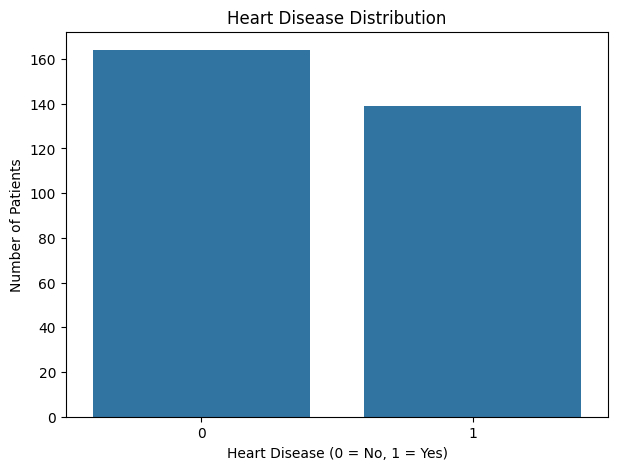

In [6]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="target")

plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")

plt.show()

In [7]:
X = df.drop("target", axis=1)
y = df["target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (303, 13)
Target shape: (303,)


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 242
Testing records: 61


In [9]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [10]:
log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_scaled, y_train)

log_predictions = log_model.predict(X_test_scaled)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [11]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [12]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Logistic Regression metrics
log_metrics = [
    accuracy_score(y_test, log_predictions),
    precision_score(y_test, log_predictions),
    recall_score(y_test, log_predictions),
    f1_score(y_test, log_predictions)
]

# Random Forest metrics
rf_metrics = [
    accuracy_score(y_test, rf_predictions),
    precision_score(y_test, rf_predictions),
    recall_score(y_test, rf_predictions),
    f1_score(y_test, rf_predictions)
]

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Logistic Regression": log_metrics,
    "Random Forest": rf_metrics
})

display(results.round(3))

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.869,0.885
1,Precision,0.812,0.839
2,Recall,0.929,0.929
3,F1-Score,0.867,0.881


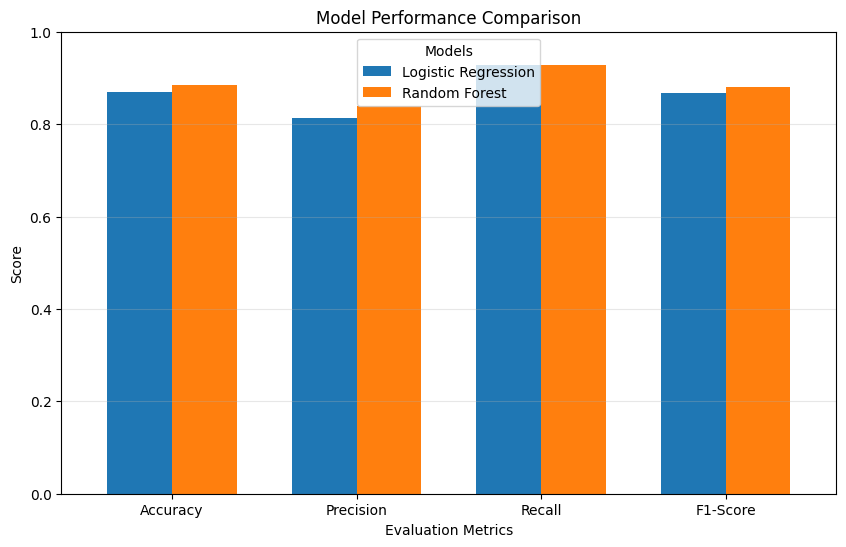

In [13]:
results_plot = results.set_index("Metric")

results_plot.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    width=0.7
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.xticks(rotation=0)
plt.legend(title="Models")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [14]:
print("LOGISTIC REGRESSION REPORT")
print(classification_report(y_test, log_predictions))

print("\nRANDOM FOREST REPORT")
print(classification_report(y_test, rf_predictions))

LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

           0       0.93      0.82      0.87        33
           1       0.81      0.93      0.87        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.88      0.87      0.87        61


RANDOM FOREST REPORT
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



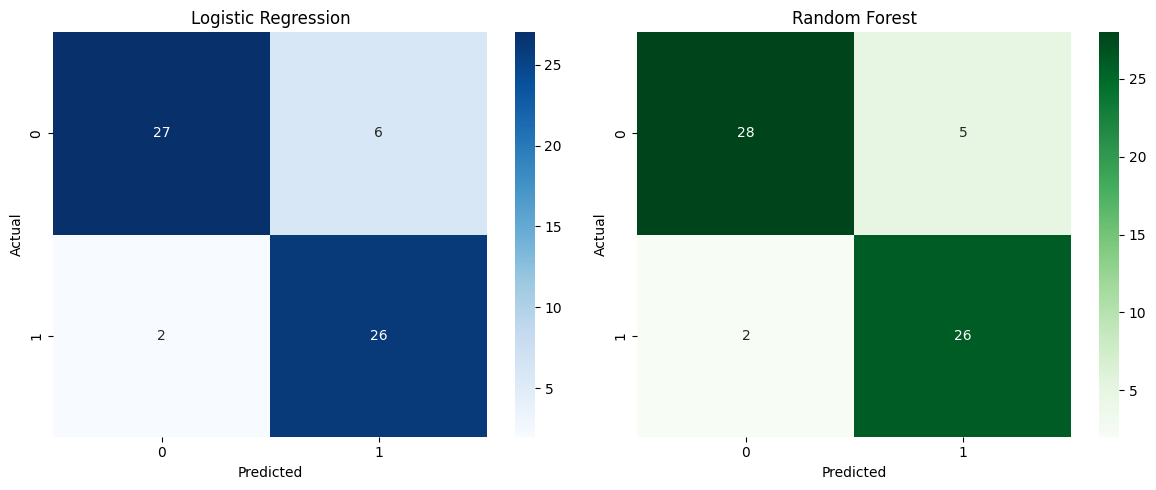

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    confusion_matrix(y_test, log_predictions),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    confusion_matrix(y_test, rf_predictions),
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=axes[1]
)

axes[1].set_title("Random Forest")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

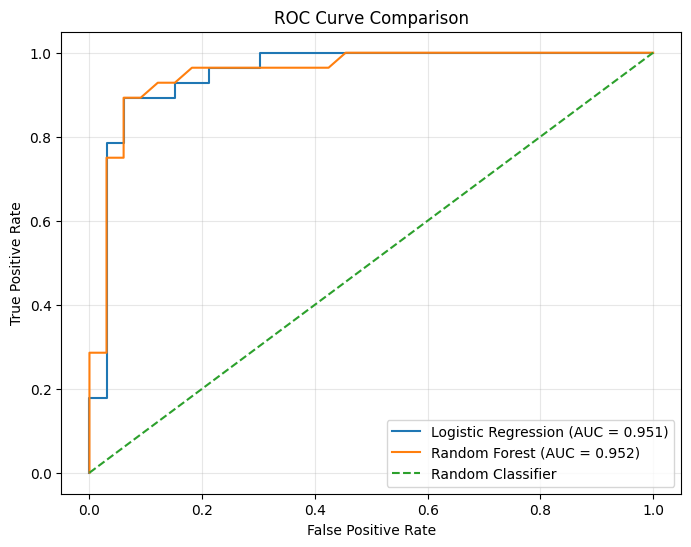

Logistic Regression AUC: 0.951
Random Forest AUC: 0.952


In [16]:
# Get prediction probabilities
log_prob = log_model.predict_proba(X_test_scaled)[:, 1]
rf_prob = rf_model.predict_proba(X_test)[:, 1]

# Calculate ROC values
fpr_log, tpr_log, _ = roc_curve(y_test, log_prob)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_prob)

# Calculate AUC
auc_log = auc(fpr_log, tpr_log)
auc_rf = auc(fpr_rf, tpr_rf)

# Plot ROC curves
plt.figure(figsize=(8, 6))

plt.plot(fpr_log, tpr_log, label=f"Logistic Regression (AUC = {auc_log:.3f})")
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc_rf:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Logistic Regression AUC:", round(auc_log, 3))
print("Random Forest AUC:", round(auc_rf, 3))

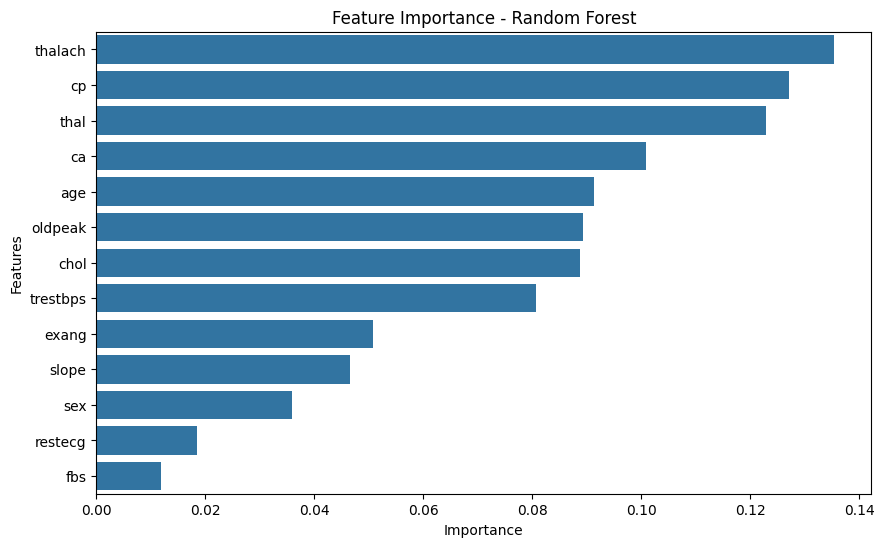

In [17]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=importance.values,
    y=importance.index
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.show()

In [18]:
sample = X_test.iloc[[0]]

prediction = rf_model.predict(sample)[0]
probability = rf_model.predict_proba(sample)[0][1]

print("Predicted class:", prediction)
print("Predicted probability:", round(probability * 100, 2), "%")

if prediction == 1:
    print("Model prediction: Heart disease indicated")
else:
    print("Model prediction: No heart disease indicated")

Predicted class: 0
Predicted probability: 24.0 %
Model prediction: No heart disease indicated


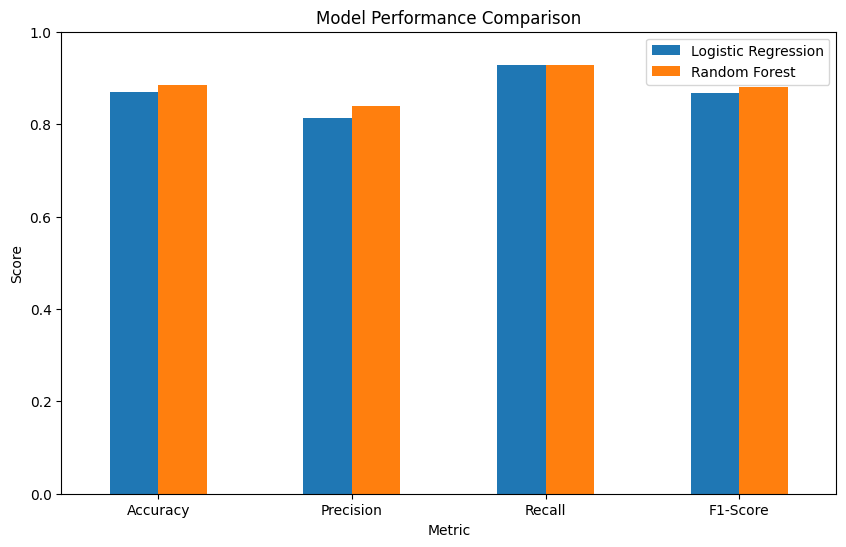

In [19]:
import os

os.makedirs("Heart_Disease_Project/visualizations", exist_ok=True)

# Save model comparison
results_plot.plot(kind="bar", figsize=(10, 6), ylim=(0, 1))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.savefig("Heart_Disease_Project/visualizations/model_comparison.png",
            bbox_inches="tight")
plt.show()

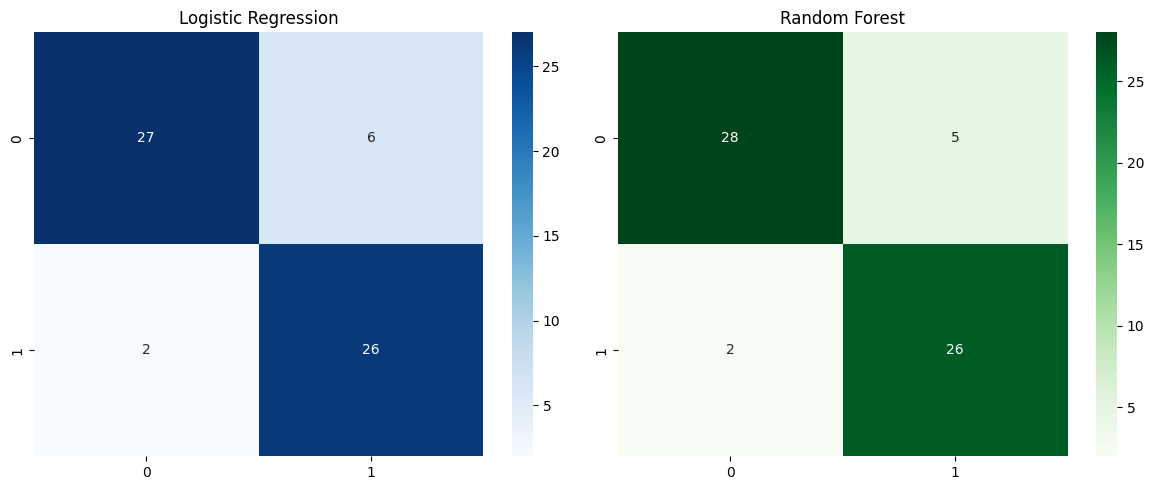

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(confusion_matrix(y_test, log_predictions),
            annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Logistic Regression")

sns.heatmap(confusion_matrix(y_test, rf_predictions),
            annot=True, fmt="d", cmap="Greens", ax=axes[1])
axes[1].set_title("Random Forest")

plt.tight_layout()
plt.savefig("Heart_Disease_Project/visualizations/confusion_matrices.png",
            bbox_inches="tight")
plt.show()

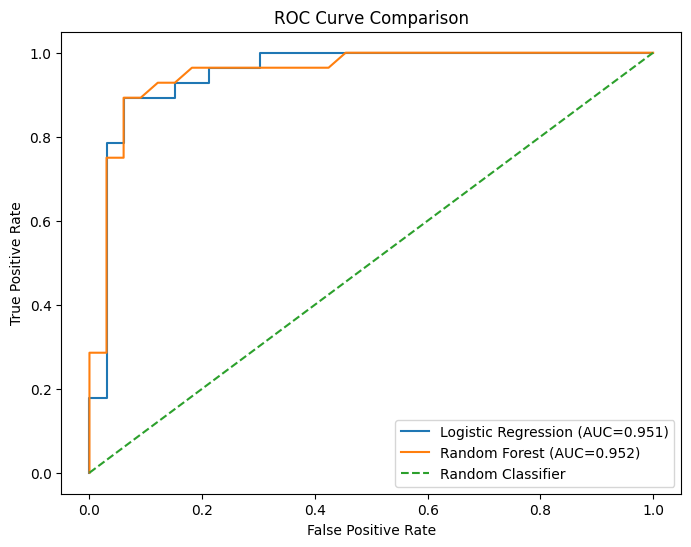

In [21]:
plt.figure(figsize=(8, 6))

plt.plot(fpr_log, tpr_log, label=f"Logistic Regression (AUC={auc_log:.3f})")
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC={auc_rf:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()

plt.savefig("Heart_Disease_Project/visualizations/roc_curve.png",
            bbox_inches="tight")
plt.show()

In [22]:
import joblib

os.makedirs("Heart_Disease_Project/models", exist_ok=True)

joblib.dump(log_model, "Heart_Disease_Project/models/logistic_regression.pkl")
joblib.dump(rf_model, "Heart_Disease_Project/models/random_forest.pkl")
joblib.dump(scaler, "Heart_Disease_Project/models/scaler.pkl")

print("Models saved successfully!")

Models saved successfully!


In [23]:
import shutil

shutil.make_archive(
    "Heart_Disease_Project",
    "zip",
    "Heart_Disease_Project"
)

print("Project ZIP created successfully!")

Project ZIP created successfully!
